Можем ли предсказать балл по ДВИ на основе остальных баллов? Какое качестве регрессионной модели, имеет ли смысл трансформировать предикторы?

Линейная модель:  [-38.09131844   0.97758993   0.44498658  -0.09179164]


/usr/local/lib/python3.7/dist-packages/statsmodels/tsa/tsatools.py:142: FutureWarning: In a future version of pandas all arguments of concat except for the argument 'objs' will be keyword-only
  x = pd.concat(x[::order], 1)
/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning
/usr/local/lib/python3.7/dist-packages/seaborn/_decorators.py:43: FutureWarning: Pass the following variables as keyword args: x, y. From version 0.12, the only valid positional argument will be `data`, and passing other arguments without an explicit keyword will result in an error or misinterpretation.
  FutureWarning


bera Jarque_beraResult(statistic=12.862320186680227, pvalue=0.0016105813256244161)
dwtest  (0.03677225934257415, 1.8904995465743804)
homo  (19.96611782636429, 0.00017250906417625502, 6.7297308619938345, 0.00016523624385133824)


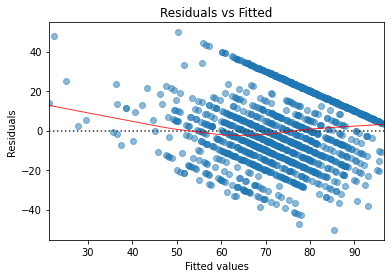

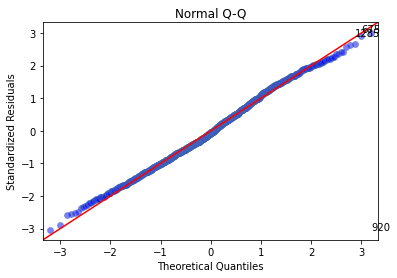

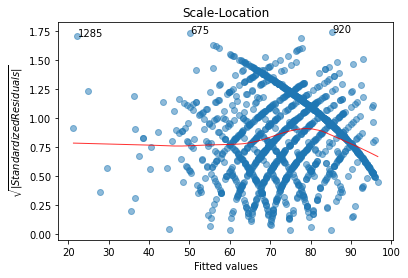

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression
from pkg_resources import yield_lines
from sklearn.linear_model import LinearRegression
import seaborn as sns
import statsmodels.api as sm
import matplotlib.pyplot as plt
from statsmodels.graphics.gofplots import ProbPlot
import scipy.stats as sps
import statsmodels.stats
import statsmodels.stats.diagnostic as dg
from dwtest import *

# достаем данные
main_df=pd.read_csv('https://raw.githubusercontent.com/zzzf64/AD/main/data3.csv',delimiter=',')
#print(main_df)
df=pd.DataFrame(main_df,columns=['Оценка.1','Оценка.2','Оценка.3','Оценка.4'])
df=df.dropna(axis='index',how='any') # убрали лишние данные
X1=pd.DataFrame(df,columns=['Оценка.2']).to_numpy().reshape(-1) # матем
X2=pd.DataFrame(df,columns=['Оценка.3']).to_numpy().reshape(-1) # физика
X3=pd.DataFrame(df,columns=['Оценка.4']).to_numpy().reshape(-1) # русский
Y=pd.DataFrame(df,columns=['Оценка.1']).to_numpy().reshape(-1) # оценка за дви


#X1=sps.boxcox(X1,lmbda=0)
#X2=sps.boxcox(X2,lmbda=0)
#X3=sps.boxcox(X3,lmbda=0)
#Y=sps.boxcox(Y,lmbda=0)
#print(np.mean(X1))
#X1=X1/np.mean(X1)
#X2/=np.mean(X2)
#X3/=np.mean(X3)
#Y/=np.mean(Y)


# Нужен ли Бокс-Кокс? Нет, потому что не надо нормировать данные, тк все оценки одинакового порядка
# (Бокс-Кокс из переменной делает какую-то степень, переменную возводят в степень лямбда)

X=np.array([X1,X2,X3])
X=np.transpose(X)
#print(X,Y)
#print('end')

#применим линейную регрессию
reg=LinearRegression().fit(X,Y)
coef=np.array([reg.intercept_])
coef=np.hstack((coef,reg.coef_))
print('Линейная модель: ',coef)
print('Наше предположение - ДВИ зависит от балла по математике')

dfX=pd.DataFrame(X)
dfY=pd.DataFrame(Y)

# берем готовый код:

# generate OLS model
model = sm.OLS(dfY, sm.add_constant(dfX))
model_fit = model.fit()

# create dataframe from X, y for easier plot handling
dataframe = pd.concat([dfX, dfY], axis=1)

# model values
model_fitted_y = model_fit.fittedvalues
# model residuals
model_residuals = model_fit.resid
# normalized residuals
model_norm_residuals = model_fit.get_influence().resid_studentized_internal
# absolute squared normalized residuals
model_norm_residuals_abs_sqrt = np.sqrt(np.abs(model_norm_residuals))
# absolute residuals
model_abs_resid = np.abs(model_residuals)
# leverage, from statsmodels internals
model_leverage = model_fit.get_influence().hat_matrix_diag
# cook's distance, from statsmodels internals
model_cooks = model_fit.get_influence().cooks_distance[0]

plot_lm_1 = plt.figure(1)
plot_lm_1.axes[0] = sns.residplot(model_fitted_y,model_residuals, data=dataframe,
                          lowess=True,
                          scatter_kws={'alpha': 0.5},
                          line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8})

plot_lm_1.axes[0].set_title('Residuals vs Fitted')
plot_lm_1.axes[0].set_xlabel('Fitted values')
plot_lm_1.axes[0].set_ylabel('Residuals')

QQ = ProbPlot(model_norm_residuals)
plot_lm_2 = QQ.qqplot(line='45', alpha=0.5, color='#4C72B0', lw=1)
plot_lm_2.axes[0].set_title('Normal Q-Q')
plot_lm_2.axes[0].set_xlabel('Theoretical Quantiles')
plot_lm_2.axes[0].set_ylabel('Standardized Residuals')
# annotations
abs_norm_resid = np.flip(np.argsort(np.abs(model_norm_residuals)), 0)
abs_norm_resid_top_3 = abs_norm_resid[:3]
for r, i in enumerate(abs_norm_resid_top_3):
    plot_lm_2.axes[0].annotate(i,
                               xy=(np.flip(QQ.theoretical_quantiles, 0)[r],
                                   model_norm_residuals[i]))

plot_lm_3 = plt.figure()
plt.scatter(model_fitted_y, model_norm_residuals_abs_sqrt, alpha=0.5)
sns.regplot(model_fitted_y, model_norm_residuals_abs_sqrt,
            scatter=False,
            ci=False,
            lowess=True,
            line_kws={'color': 'red', 'lw': 1, 'alpha': 0.8})
plot_lm_3.axes[0].set_title('Scale-Location')
plot_lm_3.axes[0].set_xlabel('Fitted values')
plot_lm_3.axes[0].set_ylabel('$\sqrt{|Standardized Residuals|}$')
# annotations
abs_sq_norm_resid = np.flip(np.argsort(model_norm_residuals_abs_sqrt), 0)
abs_sq_norm_resid_top_3 = abs_sq_norm_resid[:3]
for i in abs_norm_resid_top_3:
    plot_lm_3.axes[0].annotate(i,
                               xy=(model_fitted_y[i],
                                   model_norm_residuals_abs_sqrt[i]))
Y1=reg.predict(X)
res=Y-Y1
# print(res.mean()) -- проверяем с какой точностью
print('bera',sps.jarque_bera(res))
res1=res.reshape((-1,1))
X2=sm.add_constant(X)
# используем методы для проверки модели
print('dwtest ',dwtest(res1,X2,method='normal', matrix_inverse = False))
print('homo ',statsmodels.stats.diagnostic.het_breuschpagan(res,X2))


#по графикам -- модель адекватна (в теории), т.е. модель линейная

# -38 - свободный член; 0.97 - множитель перед математикой; 0.44 - перед физикой; -0.9 - русский
# возьмите все баллы за матем, половину за физ, вычесть чуть-чуть русского, вычесть 38 и получ оценку за дви
# с какой точностью? с хорошей, тк модель линейная (проверка выше)

# критерий харке-бера говорит, что остатки распределены не нормально (в теории 2.1.1 пункт 4, эпсилон - остатки), но это не критично
# p value маленькое

# scale location проверяет гомоскедастичность, она хорошая, тк находится близко к 0, но тест почему-то говорит, что она плохая

# критерий бройша-пагана (homo) говорит, что зависит т.к значение очень маленькое

# dwtest проверяет некореллированость ошибок
# 3% -- мало

# у нас есть гомоскедастичность по 3 графику и адекватность по 1 графику

Мы можем провести линейную регрессию (на графиках видно, что модель нормальная).

График 1. График остатков хороший, значит, модель адекватна (линейна).

График 2. QQ-plot позволяет оценить адекватность нормальной модели. Он весьма хороший, гипотеза верна

График 3. График Scale-location, позволяющий оценить гомоскедастичность, в принципе хороший, близкий к 0. Но тест, который её проверяет, говорит, что она плохая (0.00016523624385133824). Гипотеза не верна, дисперсия ошибок зависят от Х

Некоррелированность ошибок проверяет критерий Дарбина-Уотсона. P- value 3%, это мало.

Критерий Харке-Бера говорит, что ошибки распределены не нормально (pvalue=0.00161). Гипотеза не верна

Нормальности нет, преобразования (Бокса-Кокса) не улучшают ситуацию



ИТОГО
1. Адекватность есть
2. Гомоскедастичность есть
3. Некореллированность ошибок нет
4. Нормальность нет

2 из 4 необходимых условий линейной регрессии выполняется

Трансформировать предикторы не нужно, видно по графику остатков. Он похож на линейный, значит нет. Если применить преобразование Бокса-Кокса, будет даже немного хуже